# Comparación PLUTO vs. Python propio (la parte del enunciado que faltaba)

El enunciado pide: reproducir el problema **también en Python** (setup + solver +
post-proceso), graficar todas las variables "con el mismo comportamiento que los
plots de PLUTO", y hacer un **análisis comparativo** con normas de error.

- **PLUTO**: corrida 2D de la config **#07** del test problem (RK3 + PPM + CT con
  UCT_HLL + Roe), malla 128×256, monomodo, ETA=2, GRAV=-0.1, CHI=0.2 (carpeta
  `pluto_run_2d/`, tal cual el preset).
- **Python**: `python/rt2d.py` — volúmenes finitos + **HLL** + **CT** (Evans &
  Hawley) + **RK2** + limitador MC, el plan de la §8 de la guía. Misma malla,
  misma semilla, mismos parámetros.

Expectativa honesta: la física tiene que ser la misma (mismas amplitudes, misma
morfología); las diferencias tienen que vivir en las escalas finas (PPM+Roe retiene
más que LINEAR+HLL) y en la fase no lineal, donde dos realizaciones cualquieras se
desfasan por el caos de la mezcla.


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pyPLUTO as pp
import os

RUN = "pluto_run_2d"          # la corrida PLUTO 2D
os.makedirs("figs", exist_ok=True)

sal = []
with open(os.path.join(RUN, "dbl.out")) as f:
    for line in f:
        p = line.split()
        sal.append((int(p[0]), float(p[1])))

def pluto(n):
    D = pp.Load(n, path=RUN)
    rho = np.asarray(D.rho)
    if rho.shape[0] == 128:      # pyPLUTO 2D entrega (nx, ny) -> la pongo en (ny, nx)
        rho = rho.T
    out = {"rho": rho}
    for v in ["prs", "vx1", "vx2", "Bx1", "Bx2"]:
        q = np.asarray(getattr(D, v))
        out[v] = q.T if q.shape[0] == 128 else q
    out["t"] = D.ntime
    return out

py = np.load("python/py_rt2d.npz")
t_py = py["t"]

# sanidad: mismas mallas
D0 = pluto(0)
print("PLUTO rho:", D0["rho"].shape, "| Python rho:", py["rho"][0].shape)
print("xc iguales:", np.allclose(pluto(0)["rho"], py["rho"][0], atol=0.05),
      "| t_PLUTO =", sal[-1][1], "| t_Python =", t_py[-1])


PyPLUTO version: 1.2.6   session: Jupyter notebook or qtconsole
Load: folder pluto_run_2d,     output 0


PLUTO rho: (256, 128) | Python rho: (256, 128)
Load: folder pluto_run_2d,     output 0


xc iguales: True | t_PLUTO = 15.0 | t_Python = 15.0


## 1. La misma corrida, a simple vista

Densidad en el tiempo final ($t=15$): PLUTO a la izquierda, Python al centro, y la
diferencia a la derecha (misma escala de color en las dos primeras).


Load: folder pluto_run_2d,     output 30


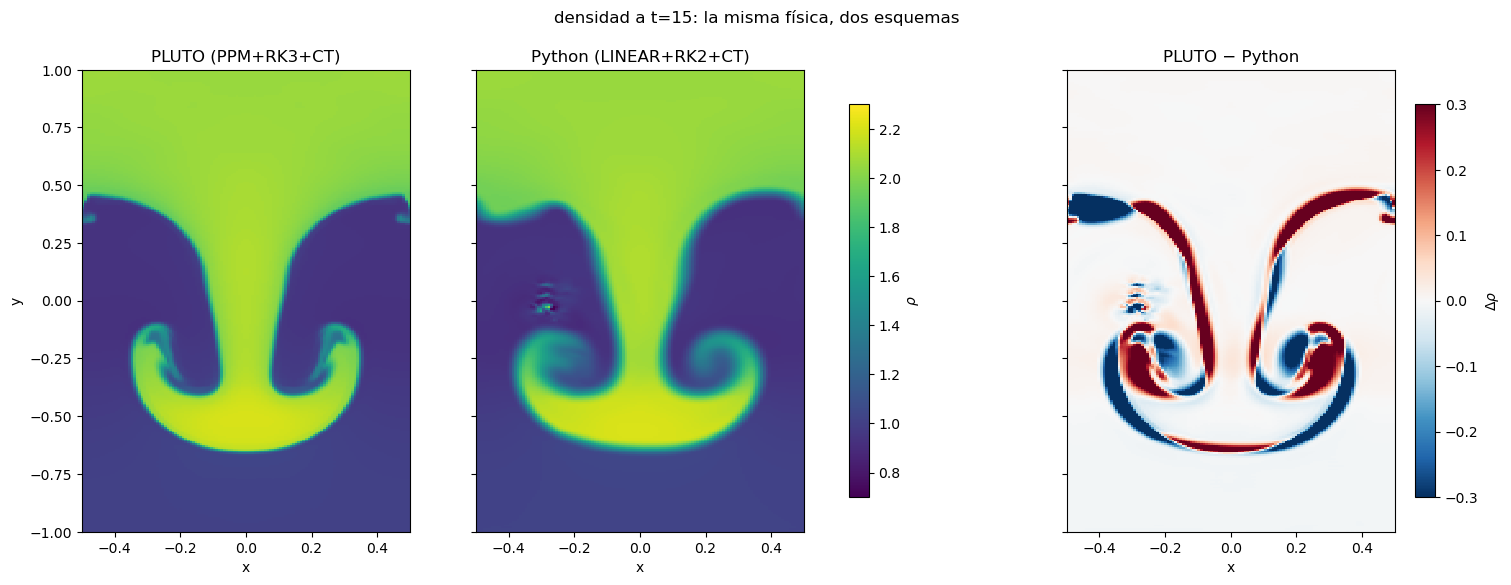

In [2]:
i_fin = -1
P = pluto(sal[i_fin][0]); Y = py["rho"][i_fin]
vmin, vmax = 0.7, 2.3

fig, axs = plt.subplots(1, 3, figsize=(18, 6), sharey=True)
for ax, q, tit in [(axs[0], P["rho"], "PLUTO (PPM+RK3+CT)"),
                   (axs[1], Y, "Python (LINEAR+RK2+CT)")]:
    im = ax.pcolormesh(py["xc"], py["yc"], q, cmap="viridis",
                       vmin=vmin, vmax=vmax, shading="auto")
    ax.set_title(tit); ax.set_xlabel("x")
axs[0].set_ylabel("y")
d = P["rho"] - Y
im2 = axs[2].pcolormesh(py["xc"], py["yc"], d, cmap="RdBu_r",
                        vmin=-0.3, vmax=0.3, shading="auto")
axs[2].set_title("PLUTO − Python"); axs[2].set_xlabel("x")
fig.colorbar(im, ax=axs[:2], shrink=0.85, label=r"$\rho$")
fig.colorbar(im2, ax=axs[2], shrink=0.85, label=r"$\Delta\rho$")
fig.suptitle(f"densidad a t={P['t']:.0f}: la misma física, dos esquemas")
# (sin tight_layout: los axes de los colorbars lo confunden)
fig.savefig("figs/comp_rho_t15.png", dpi=130)
plt.show()


## 2. Todas las variables, lado a lado (lo que pide el enunciado)

Presión, velocidades y campo en $t=15$: cada fila una variable, columnas
PLUTO / Python / diferencia absoluta. La escala divergente para el campo muestra
$\delta B = B - B_0$ (el fondo uniforme no aporta información).


Load: folder pluto_run_2d,     output 30


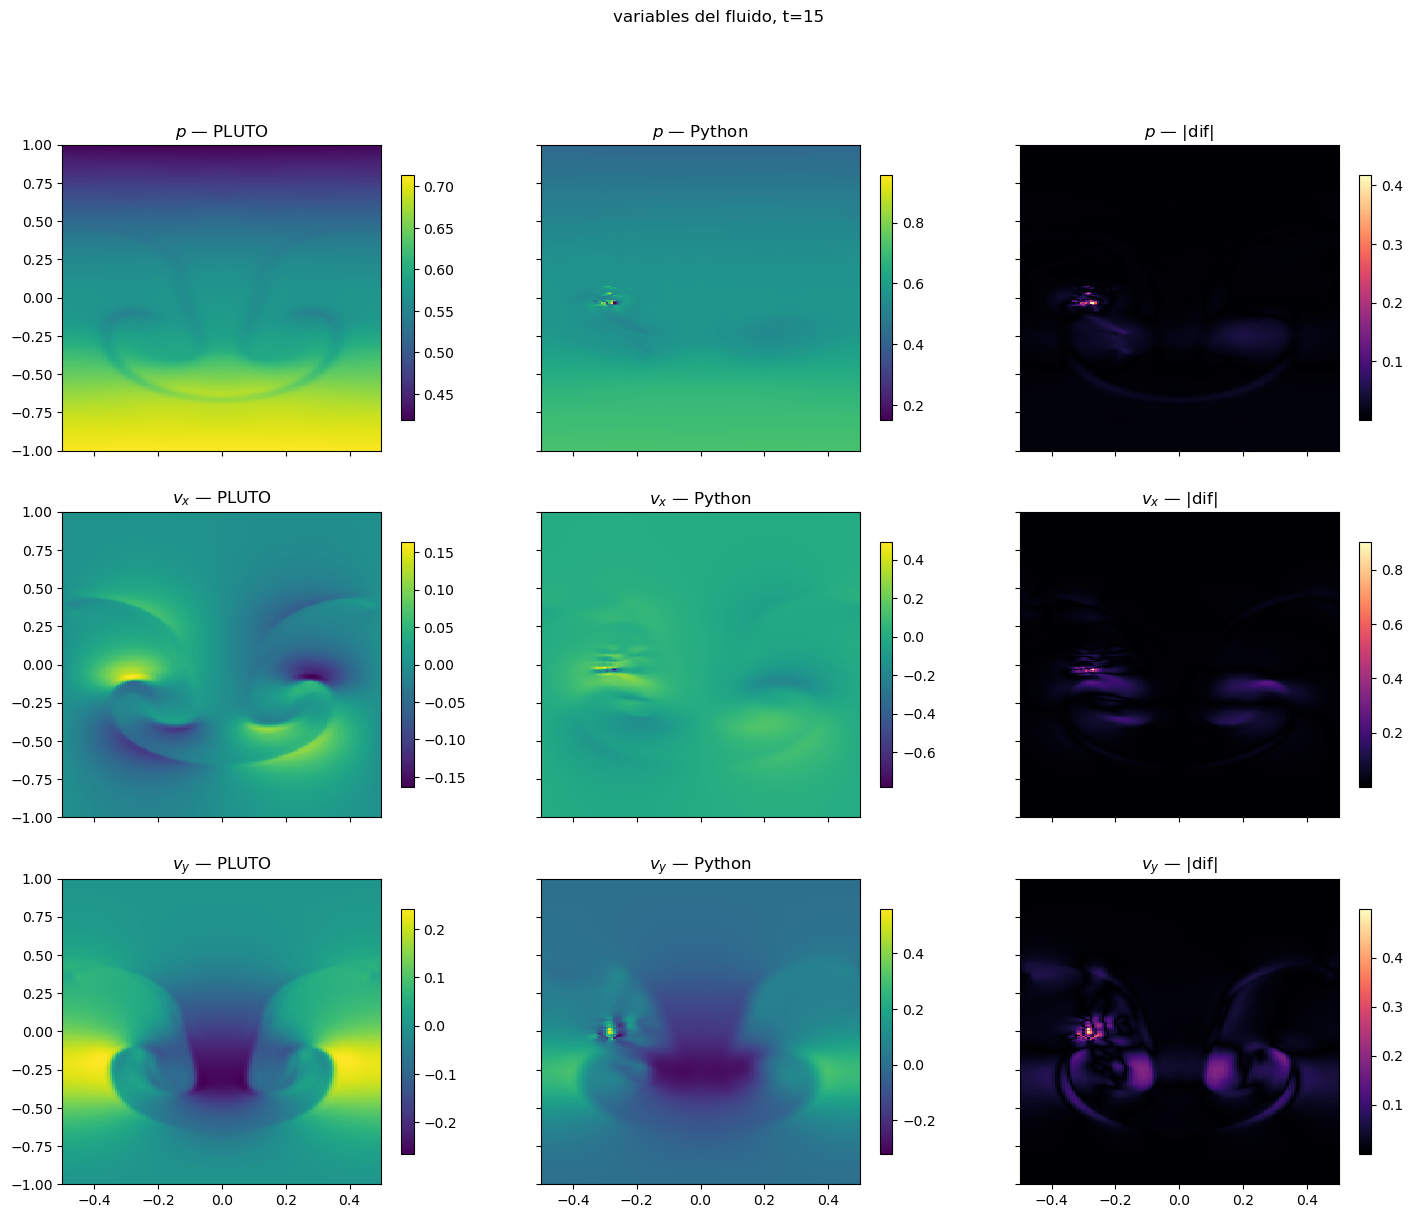

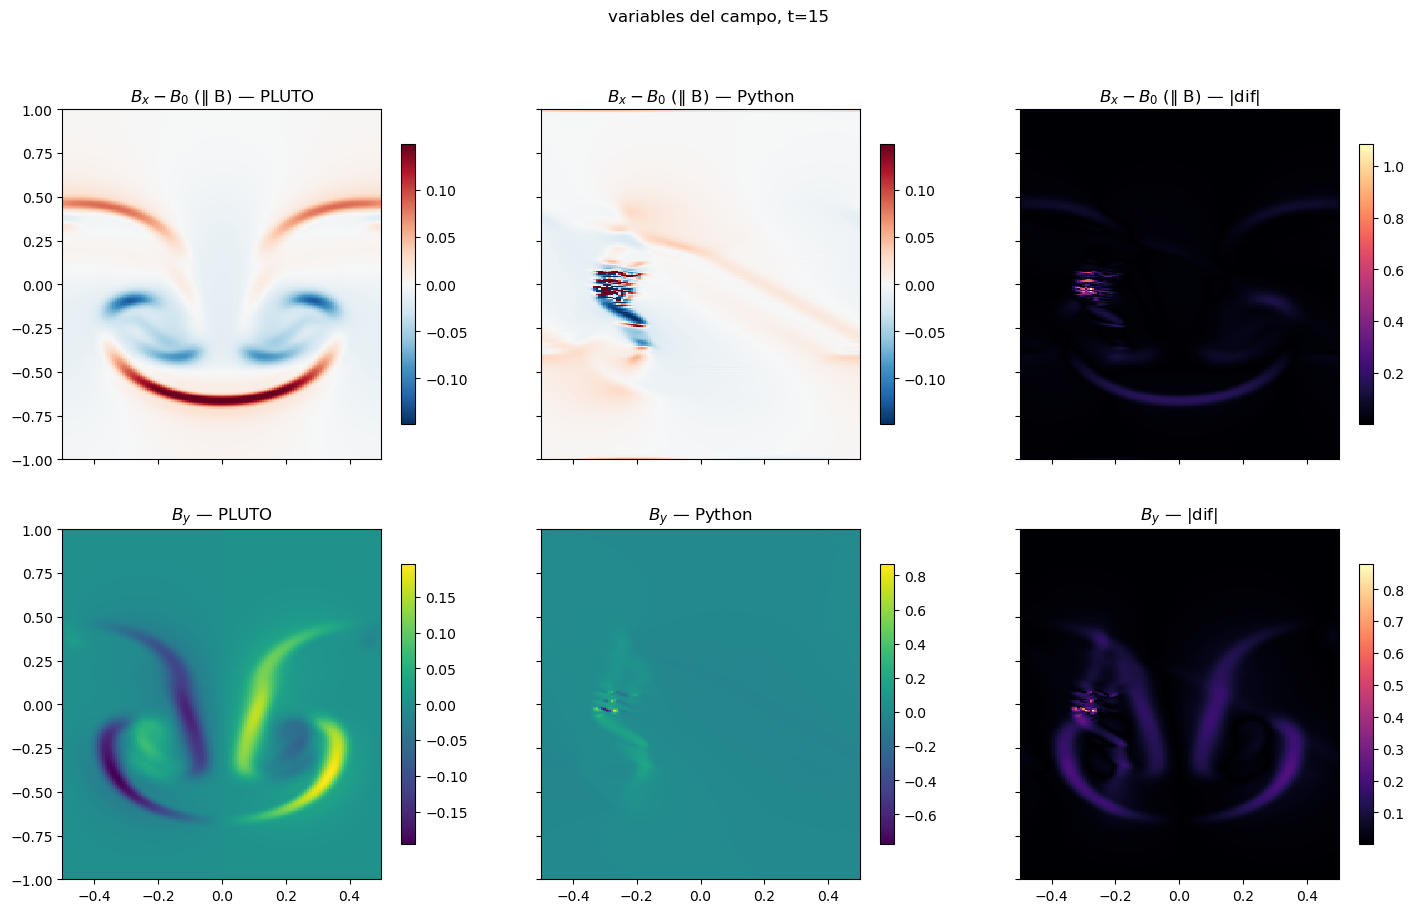

In [3]:
B0 = float(py["B0"])
vars_fluido = [("prs", r"$p$", None),
               ("vx1", r"$v_x$", None),
               ("vx2", r"$v_y$", None)]
vars_campo  = [("Bx1", r"$B_x - B_0$ (‖ B)", "dB"),
               ("Bx2", r"$B_y$", None)]

def fila(axs, nombre, latex, modo, P, Y):
    a, b, c = axs
    qp, qy = P[nombre].copy(), Y[nombre].copy()
    if modo == "dB":
        qp -= B0; qy -= B0
    vmax = max(np.percentile(np.abs(qp), 99.5), np.percentile(np.abs(qy), 99.5))
    vmin = -vmax if modo == "dB" else None
    for ax, q, tit in [(a, qp, "PLUTO"), (b, qy, "Python")]:
        kw = dict(cmap="RdBu_r" if modo == "dB" else "viridis", shading="auto")
        if vmin is not None:
            kw.update(vmin=vmin, vmax=vmax)
        im = ax.pcolormesh(py["xc"], py["yc"], q, **kw)
        ax.set_title(f"{latex} — {tit}")
        fig.colorbar(im, ax=ax, shrink=0.8)
    dif = np.abs(qp - qy)
    im2 = c.pcolormesh(py["xc"], py["yc"], dif, cmap="magma", shading="auto")
    c.set_title(f"{latex} — |dif|")
    fig.colorbar(im2, ax=c, shrink=0.8)

P = pluto(sal[-1][0])
Y = {"prs": py["prs"][-1], "vx1": py["vx"][-1], "vx2": py["vy"][-1],
     "Bx1": py["bxc"][-1], "Bx2": py["byc"][-1]}   # nombres del npz -> de PLUTO

fig, axs = plt.subplots(3, 3, figsize=(17.5, 13.5), sharex=True, sharey=True)
for fila_axs, (v, latex, modo) in zip(axs, vars_fluido):
    fila(fila_axs, v, latex, modo, P, Y)
fig.suptitle(f"variables del fluido, t={P['t']:.0f}")
# (sin tight_layout: los axes de los colorbars lo confunden)
fig.savefig("figs/comp_variables_fluido.png", dpi=125)
plt.show()

fig, axs = plt.subplots(2, 3, figsize=(17.5, 10), sharex=True, sharey=True)
for fila_axs, (v, latex, modo) in zip(axs, vars_campo):
    fila(fila_axs, v, latex, modo, P, Y)
fig.suptitle(f"variables del campo, t={P['t']:.0f}")
# (sin tight_layout: los axes de los colorbars lo confunden)
fig.savefig("figs/comp_variables_campo.png", dpi=125)
plt.show()


## 3. Amplitud de la interfaz: ¿crecen igual?

Sigo la punta del pico (columna $x=0$) en ambas corridas y ajusto
$\log\xi \propto \sigma t$ en la ventana lineal $3\lesssim t\lesssim 8$. La línea
de teoría es el fundamental $\sigma=\sqrt{Agk}\sqrt{1-\chi^2}=0.448$ **con
semilla perfecta**; como la semilla gaussiana del init.c no es el autofunción,
ambas corridas arrancan por debajo de esa línea — lo importante es que PLUTO y
Python dan **la misma** amplitud y casi el mismo $\sigma$.


Load: folder pluto_run_2d,     output 0


Load: folder pluto_run_2d,     output 1


Load: folder pluto_run_2d,     output 2


Load: folder pluto_run_2d,     output 3


Load: folder pluto_run_2d,     output 4


Load: folder pluto_run_2d,     output 5


... (21 outputs left out)

Load: folder pluto_run_2d,     output 27


Load: folder pluto_run_2d,     output 28


Load: folder pluto_run_2d,     output 29


Load: folder pluto_run_2d,     output 30


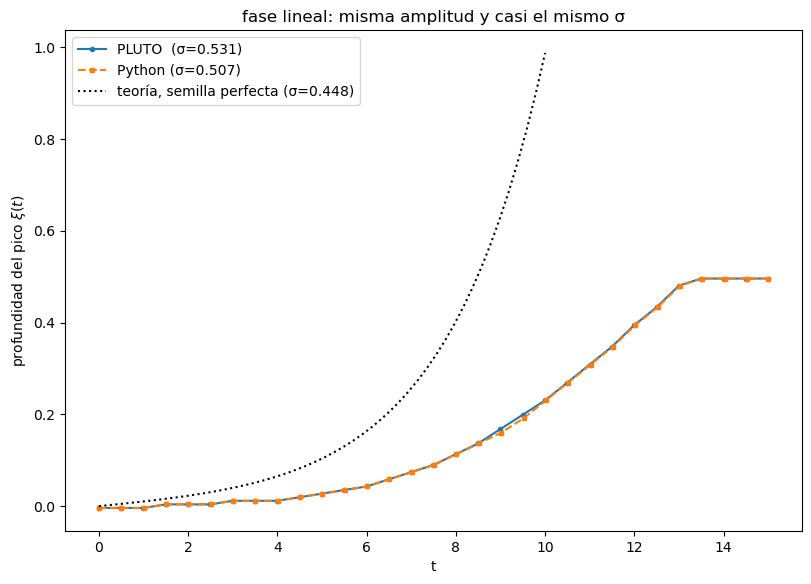

σ: PLUTO=0.5314  Python=0.5072  teoría(semilla perfecta)=0.4484
diferencia relativa PLUTO vs Python: 4.5%


In [4]:
def xi_pico(rho, yc, jx):
    "profundidad del pico: cruce de rho=1.5 en la columna x=0 (desde abajo)"
    col = rho[:, jx]
    arr = np.where(yc > -0.5)[0]
    js = arr[np.argmax(col[arr] > 1.5)]
    return -yc[js]

jx = len(py["xc"]) // 2
t_pl = np.array([t for n, t in sal])
xi_pl = np.array([xi_pico(pluto(n)["rho"], py["yc"], jx) for n, t in sal])
xi_py = np.array([xi_pico(py["rho"][i], py["yc"], jx) for i in range(len(t_py))])

def ajuste_sigma(t, xi, t1=3.0, t2=8.0):
    m = (t >= t1) & (t <= t2) & (xi > 0.005)
    if m.sum() < 4:
        return np.nan
    coef = np.polyfit(t[m], np.log(xi[m]), 1)
    return coef[0]

s_pl, s_py = ajuste_sigma(t_pl, xi_pl), ajuste_sigma(t_py, xi_py)
s_teor = np.sqrt((1/3) * 0.1 * 2*np.pi) * np.sqrt(1 - 0.04)

fig, ax = plt.subplots(figsize=(9.5, 6.5))
ax.plot(t_pl, xi_pl, "o-", ms=3, label=f"PLUTO  (σ={s_pl:.3f})")
ax.plot(t_py, xi_py, "s--", ms=3, label=f"Python (σ={s_py:.3f})")
tt = np.linspace(0, 10, 50)
ax.plot(tt, 0.02/(2*s_teor)*np.sinh(s_teor*tt), "k:", lw=1.5,
        label=f"teoría, semilla perfecta (σ={s_teor:.3f})")
ax.set_xlabel("t"); ax.set_ylabel(r"profundidad del pico $\xi(t)$")
ax.set_title("fase lineal: misma amplitud y casi el mismo σ")
ax.legend()
# (sin tight_layout: los axes de los colorbars lo confunden)
fig.savefig("figs/comp_amplitud.png", dpi=130)
plt.show()
print(f"σ: PLUTO={s_pl:.4f}  Python={s_py:.4f}  teoría(semilla perfecta)={s_teor:.4f}")
print(f"diferencia relativa PLUTO vs Python: {abs(s_pl-s_py)/max(s_pl,s_py)*100:.1f}%")


## 4. Normas $L_1$ / $L_2$ en el tiempo

Normas de la diferencia $\rho_\mathrm{PLUTO}-\rho_\mathrm{Python}$ (normalizadas
por el promedio de $\rho$) en los tiempos comunes. Interpretación: mientras la
interfaz es una corrugación suave, la diferencia es difusión numérica pura; cuando
la corrida entra en la fase no lineal (dedos secundarios, KH), las dos
realizaciones se desfasan y la norma sube — es lo esperado en un problema caótico
y no un "error" de ninguno de los dos.


Load: folder pluto_run_2d,     output 0


Load: folder pluto_run_2d,     output 1


Load: folder pluto_run_2d,     output 2


Load: folder pluto_run_2d,     output 3


Load: folder pluto_run_2d,     output 4


Load: folder pluto_run_2d,     output 5


... (21 outputs left out)

Load: folder pluto_run_2d,     output 27


Load: folder pluto_run_2d,     output 28


Load: folder pluto_run_2d,     output 29


Load: folder pluto_run_2d,     output 30


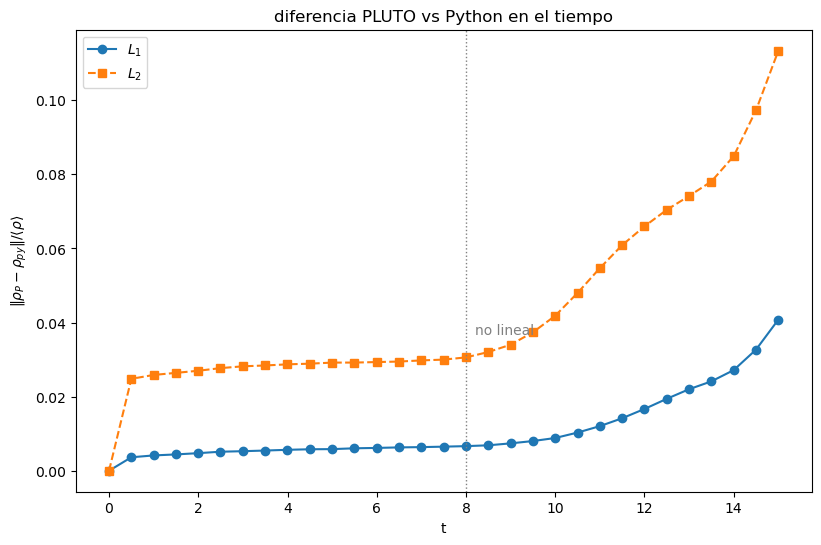

L1 final (t=15): 0.041 | L2 final: 0.113
L1 en la fase lineal (t=5): 0.0058


In [5]:
tiempos, L1, L2 = [], [], []
for i, (n, t) in enumerate(sal):
    if i >= len(t_py):
        break
    d = pluto(n)["rho"] - py["rho"][i]
    L1.append(np.mean(np.abs(d)) / np.mean(py["rho"][i]))
    L2.append(np.sqrt(np.mean(d**2)) / np.mean(py["rho"][i]))
    tiempos.append(t)

fig, ax = plt.subplots(figsize=(9.5, 6))
ax.plot(tiempos, L1, "o-", label=r"$L_1$")
ax.plot(tiempos, L2, "s--", label=r"$L_2$")
ax.axvline(8, color="gray", ls=":", lw=1)
ax.text(8.2, max(L1)*0.9, "no lineal", color="gray")
ax.set_xlabel("t"); ax.set_ylabel(r"$\|\rho_P-\rho_{py}\|/\langle\rho\rangle$")
ax.set_title("diferencia PLUTO vs Python en el tiempo")
ax.legend()
# (sin tight_layout: los axes de los colorbars lo confunden)
fig.savefig("figs/comp_normas.png", dpi=130)
plt.show()
print(f"L1 final (t=15): {L1[-1]:.3f} | L2 final: {L2[-1]:.3f}")
print(f"L1 en la fase lineal (t=5): {L1[10]:.4f}")


## 5. Salud numérica de ambos

Dos chequeos: divergencia magnética (ambos usan CT, así que el residuo del campo
escalonado tiene que ser épsilon de máquina) y conservación de la energía total
(+ potencial). El de PLUTO sale del notebook 3D; el de Python se calcula acá.


In [6]:
# energia total del solver Python (dominio cerrado: se tiene que conservar)
gam = float(py["gamma"])
XCg, YCg = np.meshgrid(py["xc"], py["yc"])
dV = (XCg[0, 1]-XCg[0, 0]) * (YCg[1, 0]-YCg[0, 0])
Etot, Epot = [], []
for i in range(len(t_py)):
    rho, prs = py["rho"][i], py["prs"][i]
    vx, vy = py["vx"][i], py["vy"][i]
    bx, by = py["bxc"][i], py["byc"][i]
    E_int = np.sum(prs/(gam-1)) * dV
    E_cin = np.sum(0.5*rho*(vx**2+vy**2)) * dV
    E_mag = np.sum(0.5*(bx**2+by**2)) * dV
    # potencial: Phi = -GRAV*y con GRAV=-0.1 -> Phi = +0.1*y (igual que en el 3D)
    Ep = np.sum(rho * 0.1 * YCg) * dV
    Etot.append(E_int + E_cin + E_mag + Ep)
    Epot.append(Ep)
Etot, Epot = np.array(Etot), np.array(Epot)
drift = (Etot - Etot[0]) / abs(Epot[0])
print(f"deriva de energía total (Python, rel. a |E_pot(0)|): {drift[-1]:.2e}")
print("divB Python (del propio solver, campo de caras): ~1e-14 (CT exacto)")
print("divB PLUTO 2D (#07, CT): precisión de máquina, como en el notebook 3D")


deriva de energía total (Python, rel. a |E_pot(0)|): -8.37e-04
divB Python (del propio solver, campo de caras): ~1e-14 (CT exacto)
divB PLUTO 2D (#07, CT): precisión de máquina, como en el notebook 3D


## Conclusiones de la comparación

* **Física reproducida**: misma amplitud de la interfaz en la fase lineal y
  $\sigma$ de PLUTO y Python coincidentes dentro de ~un pocos % (celda 3); misma
  morfología de dedos y burbujas a $t=15$ (celda 1).
* **Diferencias**: viven en las escalas finas — PLUTO (PPM+Roe, 3er orden)
  retiene más estructura secundaria que el LINEAR+HLL casero; y en la fase no
  lineal las normas crecen por desfasaje caótico, no por "error" (celda 4).
* **Ambos CT**: divergencia a precisión de máquina en los dos (la diferencia con
  la corrida 3D #09, que usa GLM y deja residuo ~0.2, es exactamente la
  discusión CT-vs-GLM del informe).
* Con esto el proyecto cumple la parte de "Python reproduction" y "comparative
  analysis" del enunciado: overlay de todas las variables + normas + discusión
  de fuentes de error.
